**Building ensemble classifiers models from MotherCV**
---------------------------------------------
This notebook shows how to
1. Build a Mother pipeline and collect its fitted fold estimators using `mother_cv`.
2. Use a CV-derived ensemble as the final model in a Mother pipeline.
3. Predict labels and uncertainty through the pipeline's `predict_uncertainty()` interface.

In [14]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import FunctionTransformer
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mother import ml
from mother.ml.ensembles.cvEnsemble import EnsembleAverageUncertaintyClassifier, EnsembleDerivedUncertaintyClassifier
import mother.pipeline_utils as mother_takes_care

# Prepare data

In [15]:
df_data, df_targets = load_breast_cancer(return_X_y=True, as_frame=True)
print(f"Downloaded dataset with {df_data.shape[0]} samples and {df_data.shape[1]} features")
print(f"The target we want to predict has {len(np.unique(df_targets))} unique classes: {np.unique(df_targets)}")

Downloaded dataset with 569 samples and 30 features
The target we want to predict has 2 unique classes: [0 1]


In [16]:
X_train, X_test, y_train, y_test = train_test_split(df_data, df_targets, test_size=0.2, random_state=42)

print(f"Training set has {X_train.shape[0]} samples and {X_train.shape[1]} features")
print(f"Test set has {X_test.shape[0]} samples and {X_test.shape[1]} features")

Training set has 455 samples and 30 features
Test set has 114 samples and 30 features


# Cross-Validation

In [17]:
model = ml.PipelineWithHyperparameterRooting(
    steps=[
        ("identity", FunctionTransformer(feature_names_out="one-to-one")),
        ("classifier", ml.CatboostClassifierMother(random_seed=42, silent=True)),
    ]
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

df_cv, estimators_dict = mother_takes_care.mother_cv(
    estimator=model, X=X_train, y=y_train, cv=cv, return_estimators=True
)

In [18]:
df_cv.head()

,pred_target,pred_proba_0,pred_proba_1,pred_knowledge_uncertainty,pred_data_uncertainty,pred_total_uncertainty,target,iteration,test_index
68,1,0.396323,0.603677,0.010003,0.607297,0.6173,1,0,0
181,0,0.999922,0.000078,0.000006,0.001224,0.001229,0,4,1
63,1,0.000302,0.999698,0.000019,0.003931,0.00395,1,2,2
248,1,0.002761,0.997239,0.000046,0.023393,0.023439,1,1,3
60,1,0.000916,0.999084,0.000081,0.011182,0.011263,1,3,4


In [19]:
estimators_dict

{'estimators': [PipelineWithHyperparameterRooting(steps=[('identity',
                                            FunctionTransformer(feature_names_out='one-to-one')),
                                           ('classifier',
                                            CatboostClassifierMother(auto_class_weights='Balanced', boosting_type='Plain', bootstrap_type='MVS', grow_policy='SymmetricTree', learning_rate=0.03, loss_function='Logloss', max_depth=6, posterior_sampling=True, random_seed=42, random_strength=1, silent=True))]),
  PipelineWithHyperparameterRooting(steps=[('identity',
                                            FunctionTransformer(feature_names_out='one-to-one')),
                                           ('classifier',
                                            CatboostClassifierMother(auto_class_weights='Balanced', boosting_type='Plain', bootstrap_type='MVS', grow_policy='SymmetricTree', learning_rate=0.03, loss_function='Logloss', max_depth=6, posterior_sampling=Tr

> Each estimator returned from mother_cv is a Mother pipeline, based on a Catboost classification model.

# Predict with individual single estimator
For comparison purposes, we train the same base model on the full training dataset. 

In [20]:
model.fit(X_train, y_train)

model_prediction = model.predict_uncertainty(X_test)

# Predict with ensemble model

To predict with an ensemble based on fitted estimators from CV, there are currently two options available:
- `EnsembleDerivedUncertaintyClassifier`: derives uncertainty from ensemble-level probabilities. The uncertainty method can be set explicitly. The default option "entropy" calculates decomposed uncertainty by mutual information between the distributions of average member vs. ensemble probability predictions.
- `EnsembleAverageUncertaintyClassifier`: averages uncertainty outputs from individual ensemble estimators.

Probabilities are predicted on ensemble-level by averaging member probabilities per sample in each case. Each ensemble is the final estimator in a `PipelineWithHyperparameterRooting`, so pipeline prediction methods delegate to the ensemble.

The cross-validation base estimator and both ensemble variants are Mother pipelines. Each fold pipeline is fitted only on its training partition, then the combined ensemble pipeline aggregates the fitted fold pipelines and predicts on the test set. The ensemble's `fit` is a no-op because its members are already fitted. The independent test split is kept separate from cross-validation.

```text
Full dataset 
│
├── Training set (80%)
│   │
│   └── 5-fold cross-validation
│       ├── Fold 1: [Validation] [Training] [Training] [Training] [Training] -> fitted Estimator 1 ┐
│       ├── Fold 2: [Training] [Validation] [Training] [Training] [Training] -> fitted Estimator 2 |
│       ├── Fold 3: [Training] [Training] [Validation] [Training] [Training] -> fitted Estimator 3 ├── Ensemble
│       ├── Fold 4: [Training] [Training] [Training] [Validation] [Training] -> fitted Estimator 4 |
│       └── Fold 5: [Training] [Training] [Training] [Training] [Validation] -> fitted Estimator 5 ┘
│
└── Independent test set (20%)
    └── Held out during cross-validation; used for final evaluation of ensemble
```

### Class relationships in `cvEnsemble.py`

```text
                        ┌──────────────────────────────┐
                        │ AbstractMotherPipeline       │
                        │ (Mother estimator API)       │
                        └──────────────▲───────────────┘
                                       │
                        ┌──────────────┴───────────────┐
                        │ CVEnsembleClassifierMother   │
                        └──────────────▲───────────────┘
                           ┌───────────┴───────────┐
                           │                       │
┌────────────────────────────────────┐  ┌─────────────────────────────────────┐
│EnsembleAverageUncertaintyClassifier│  │ EnsembleDerivedUncertaintyClassifier│
|------------------------------------|  |-------------------------------------|
|Averages member probabilities and   |  |Averages member probabilities and    |
|averages their uncertainty outputs. |  |derives uncertainty from the ensemble|
└────────────────────────────────────┘  |level predictions with a specified   | 
                                        |`uncertainty_method`                 |
                                        └─────────────────────────────────────┘
```

### Mother pipeline compatibility
```text
PipelineWithHyperparameterRooting
                  │ contains
                  ▼
       either ensemble classifier
                  │
                  ├── fit(X, y)                  # no-op: members are already fitted
                  ├── predict(X)                 # delegates to ensemble predictions
                  └── predict_uncertainty(X)     # delegates to ensemble uncertainty
```

### EnsembleDerivedUncertaintyClassifier

In [21]:
ensemble_derived = ml.PipelineWithHyperparameterRooting(
    steps=[("ensemble", EnsembleDerivedUncertaintyClassifier(estimators=estimators_dict["estimators"]))]
)

ensemble_prediction_derived = ensemble_derived.predict_uncertainty(X=X_test, ensemble__uncertainty_method="entropy")

In [22]:
ensemble_averaging = ml.PipelineWithHyperparameterRooting(
    steps=[("ensemble", EnsembleAverageUncertaintyClassifier(estimators=estimators_dict["estimators"]))]
)

ensemble_prediction_averaging = ensemble_averaging.predict_uncertainty(X=X_test)

## Evaluation

In [23]:
y_pred_base = model_prediction["pred"]
acc_base = accuracy_score(y_test, y_pred_base)
print(f"Accuracy (baseline): {acc_base:.4f} with full training set usage")

Accuracy (baseline): 0.9737 with full training set usage


In [24]:
y_pred_derived = ensemble_prediction_derived["pred"]
y_pred_averaging = ensemble_prediction_averaging["pred"]

# compute accuracy
acc_derived = accuracy_score(y_test, y_pred_derived)
acc_averaging = accuracy_score(y_test, y_pred_averaging)
print(f"Accuracy (derived): {acc_derived:.4f}; Accuracy (averaging): {acc_averaging:.4f}")

Accuracy (derived): 0.9737; Accuracy (averaging): 0.9737


> As probabilities and label predictions are commonly aggregated from estimators, accuracy scores are identical for **derived** and **averaging** ensemble.

> In comparison to a single model trained on the full training set, evaluation on the final test set shows equal accuracies. This is not unexpected, as ensemble members are each trained on different subsets of the full training data, using a fraction of 4/5 of training samples with 5 CV folds. 

In [25]:
print("Log loss evaluated on final test set")
for name, prediction in [
    ("single baseline model", model_prediction),
    ("ensemble (average)", ensemble_prediction_averaging),
    ("ensemble (derived)", ensemble_prediction_derived),
]:
    ll = log_loss(y_test, prediction[["proba_0", "proba_1"]])
    print(f"{name}:\t{ll:.4f}")

Log loss evaluated on final test set
single baseline model:	0.0606
ensemble (average):	0.0689
ensemble (derived):	0.0689


> Looking at log loss (↓), which takes class probabilities into account, we see a small difference between the full-data trained baseline and the ensemble models.

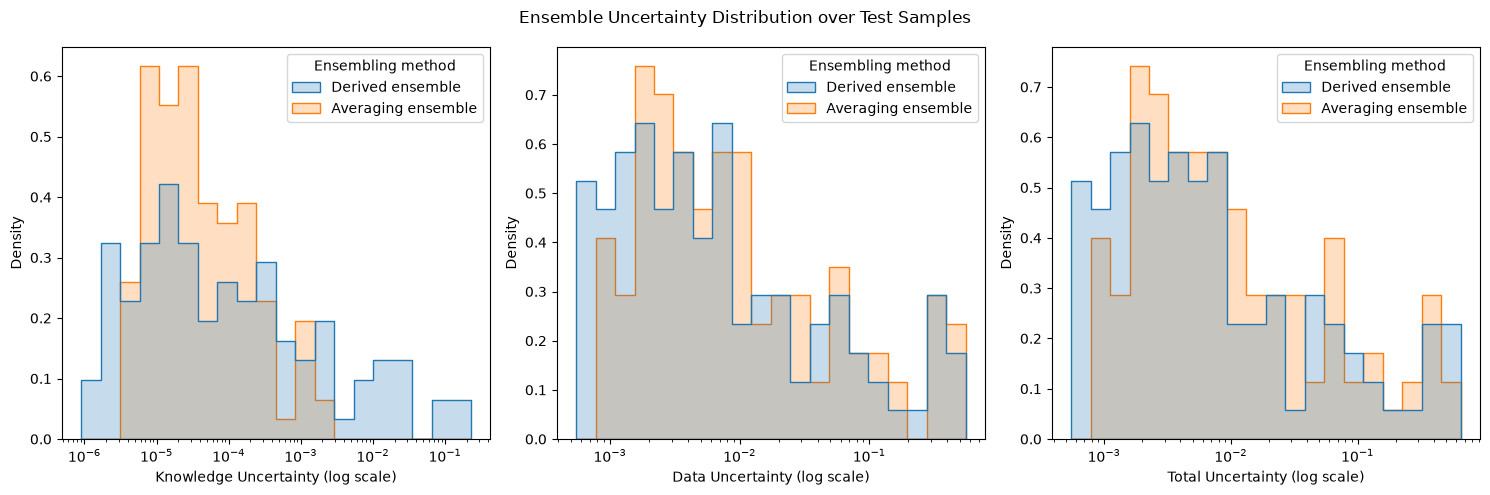

In [26]:
uncertainty_types = ["knowledge_uncertainty", "data_uncertainty", "total_uncertainty"]
ensemble_uncertainties = pd.concat(
    {
        "Derived ensemble": ensemble_prediction_derived[uncertainty_types],
        "Averaging ensemble": ensemble_prediction_averaging[uncertainty_types],
    },
    names=["Ensembling method"],
).reset_index(level="Ensembling method")

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for uncertainty_type in uncertainty_types:
    ax = axs[uncertainty_types.index(uncertainty_type)]
    sns.histplot(
        ax=ax,
        data=ensemble_uncertainties,
        x=uncertainty_type,
        hue="Ensembling method",
        bins=20,
        stat="density",
        common_norm=False,
        element="step",
        fill=True,
        log_scale=(True, False),
    )
    ax.set_xlabel(f"{uncertainty_type.replace('_', ' ').title()} (log scale)")
    ax.set_ylabel("Density")

fig.suptitle("Ensemble Uncertainty Distribution over Test Samples")
plt.tight_layout()
plt.show()

> As uncertainty estimation uses different strategies, distributions do not fully overlap between ensemble classes. The derived ensemble uncertainty (blue) spans a wider value range for knowledge uncertainty. The derived method captures disagreement among CV estimators through ensemble-level probabilities, whereas the averaging method averages each estimator’s uncertainty estimates. Those estimates rely on CatBoost’s virtual ensembles here, with a virtual ensemble using model subsets as base estimators. A smaller range of uncertainty values is therefore expected when averaging CatBoost uncertainty estimates on ensemble level (orange).